# 2.1 A synthetic marimba C3, analysed with laborch

In notebook **1.2** a C3 "marimba" tone was built from three sine partials, the 1st, 4th and 10th, with amplitudes 1, ½ and ¼. (An ideally tuned marimba bar has overtones near 4× and 10× the fundamental.) The notebook then took its FFT and tried to rebuild the sound from the power spectrum.

This notebook repeats that experiment with the `laborch` package and takes it one step further: the synthetic tone becomes a **Target**, and NNLS asks which real marimba notes from the McGill Bank reproduce it.

| Step | laborch function |
| --- | --- |
| build the tone | `laborch.synth.tone` |
| averaged spectrum, Bank format | `laborch.spectra.make_fft` |
| find its partials | `laborch.spectra.spectral_peaks` |
| decompose onto marimba sounds | `laborch.nnls_fit`, `laborch.dot` |
| hear the result | `laborch.audio.render_fit`, `laborch.synth.spectrum_to_audio` |

In [1]:
import sys
sys.path.insert(0, '..')            # or: pip install -e ..

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

from laborch import Bank, nnls_fit, dot, parse_name, config
from laborch.bank import frequencies
from laborch.spectra import make_fft, spectral_peaks
from laborch.synth import tone, spectrum_to_audio
from laborch.audio import render_fit

sr = config.SAMPLE_RATE
f = frequencies()                   # Hz of each spectrum bin

## 1. Build the tone

Notebook 1.2 used 130 Hz. Here the fundamental comes from the Bank's own pitch for `mrb-c3`, so it lines up exactly with the recorded marimba: C3 = 130.81 Hz (MIDI 48, with A4 = 440 Hz).

f0 = 130.81 Hz; partials at [130.8, 523.3, 1308.1] Hz


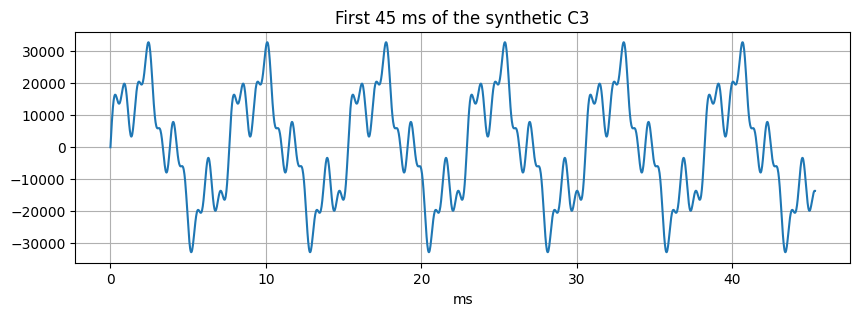

In [2]:
f0 = parse_name("mrb-c3-ord-mf").freq
partials, amps = [1, 4, 10], [1.0, 0.5, 0.25]

note = tone(f0, partials, amps, seconds=1.0, peak=2**15 - 1)   # 16-bit scale, as in 1.2
print(f"f0 = {f0:.2f} Hz; partials at", [round(p * f0, 1) for p in partials], "Hz")

plt.figure(figsize=(10, 3))
t = np.arange(2000) / sr
plt.plot(1000 * t, note[:2000])
plt.xlabel("ms"); plt.title("First 45 ms of the synthetic C3"); plt.grid()

In [3]:
Audio(note, rate=sr)

## 2. Its spectrum, in Bank format

`make_fft` applies the same recipe that built every spectrum in `FFTBank`:

1. trim 15% from each end;
2. average 4,096-sample Hamming windows, stepping 512 samples at a time;
3. keep 2,048 bins of 10.77 Hz;
4. normalize to unit sum.

The result can be compared directly with any Bank sound.

In [4]:
spec = make_fft(note)

for hz, rel in spectral_peaks(spec, max_hz=3000):
    print(f"{hz:7.1f} Hz   partial {hz / f0:5.2f}   relative height {rel:.2f}")

  129.2 Hz   partial  0.99   relative height 1.00
  527.6 Hz   partial  4.03   relative height 0.45
 1302.8 Hz   partial  9.96   relative height 0.21


The three peaks sit within one bin (10.77 Hz) of 1×, 4× and 10× f0. Their heights come out at about 1 : 0.45 : 0.21 rather than 1 : 0.5 : 0.25. Each partial falls at a slightly different spot relative to the bin centres, so the Hamming window spreads its energy over neighbouring bins by different amounts.

## 3. Compare with the real marimba C3

McGill mrb-c3 peaks (as multiples of f0):
   0.99 x f0   relative height 1.00
   4.03 x f0   relative height 0.09

shape similarity (cosine) synthetic vs real: 0.904


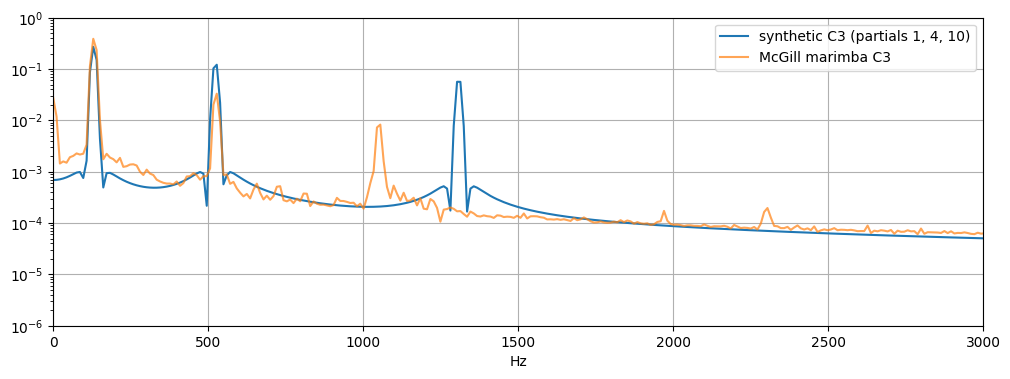

In [5]:
bank = Bank.load()
real = bank.spectrum("mrb-c3-ord-mf")

print("McGill mrb-c3 peaks (as multiples of f0):")
for hz, rel in spectral_peaks(real, rel_height=0.05, max_hz=3000):
    print(f"  {hz / f0:5.2f} x f0   relative height {rel:.2f}")

cos = spec @ real / np.linalg.norm(spec) / np.linalg.norm(real)
print(f"\nshape similarity (cosine) synthetic vs real: {cos:.3f}")

plt.figure(figsize=(12, 4))
plt.semilogy(f, spec, label="synthetic C3 (partials 1, 4, 10)")
plt.semilogy(f, real, label="McGill marimba C3", alpha=0.7)
plt.xlim(0, 3000); plt.ylim(1e-6, 1); plt.xlabel("Hz"); plt.legend(); plt.grid()

The recorded bar is dominated by its fundamental. Its 4th partial is only 0.09 of the fundamental's height, and the 10th does not reach 5%. The synthetic tone (0.45 and 0.21) is therefore much brighter than a real marimba C3, and one marimba note cannot match it. The decomposition below shows how NNLS makes up the difference.

## 4. Decompose the Target onto the marimba

The Palette is all 56 marimba sounds in the Bank, and NNLS finds non-negative weights α so that Σ αⱼ Xⱼ ≈ T.

In [6]:
palette = bank.select(instruments=["mrb"])
fit = nnls_fit(palette, spec)
print(fit.summary(5))

nnls: 56 sounds, relative error 0.230
    0.6571  mrb-c3-ord-mf
    0.2982  mrb-c5-ord-mf
    0.1481  mrb-e6-ord-mf
    0.0362  mrb-b2-ord-mf


| Sound | What it supplies |
| --- | --- |
| `mrb-c3` | the fundamental, and the bar's own 4th partial |
| `mrb-c5` | more energy at the 4th partial (C5 is two octaves above C3, so its fundamental lands exactly there) |
| `mrb-e6` | the 10th partial: 10 × 130.8 = 1,308 Hz, close to E6 (1,318.5 Hz) |

So NNLS "orchestrates" the synthetic tone as a marimba C3, reinforced by notes on its strongest overtones. That is the classic technique of doubling partials to colour a sound.

**DOT** (RH2009's projection method) scores each sound on its own. With `normalize=True` the score is the cosine similarity:

In [7]:
dot(palette, spec, normalize=True).ranked(5)

[('mrb-c3-ord-mf', 0.9036229445088554),
 ('mrb-b2-ord-mf', 0.7155226192601473),
 ('mrb-cs3-ord-mf', 0.6526586281336829),
 ('mrb-c5-ord-mf', 0.42134408914580485),
 ('mrb-as2-ord-mf', 0.35269686581590237)]

DOT ranks `mrb-c3` first (0.90), followed by its neighbours B2 and C♯3. DOT can only say which single sound is most similar. Unlike NNLS, it cannot find the combination with C5 and E6.

## 5. A wider Ensemble

The Palette now includes all the mallet instruments: vibraphone, xylophone, marimba, glockenspiel and crotales.

In [8]:
mallets = bank.select(instruments=["vib", "xyl", "mrb", "glk", "cro"])
fit_m = nnls_fit(mallets, spec)
print(fit_m.summary(5))

nnls: 188 sounds, relative error 0.212
    0.6492  mrb-c3-ord-mf
    0.1846  vib-c5-bwd-mf
    0.1489  mrb-e6-ord-mf
    0.1016  mrb-c5-ord-mf
    0.0431  mrb-b2-ord-mf


With more colours available, NNLS swaps part of the marimba C5 for a **bowed vibraphone C5** (`vib-c5-bwd-mf`), whose purer tone suits the 4th partial. The error also drops slightly.

nnls: 3 sounds, relative error 0.232
    0.6854  mrb-c3-ord-mf
    0.2961  mrb-c5-ord-mf
    0.1483  mrb-e6-ord-mf


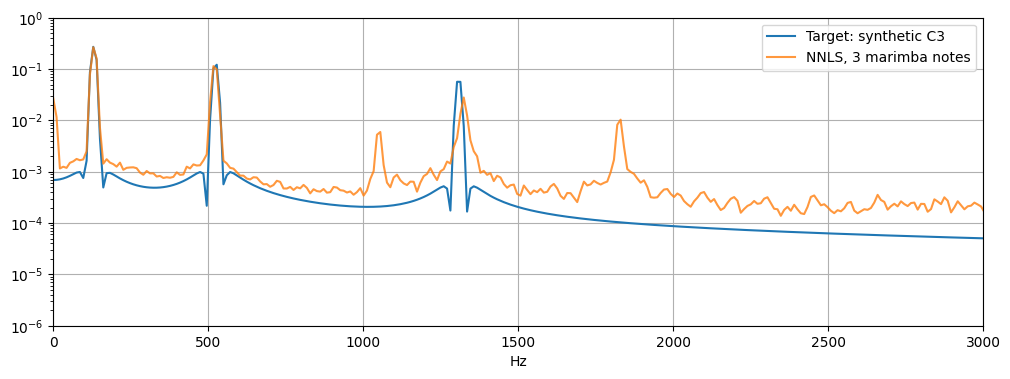

In [9]:
best = fit.top(3, refit=True)
print(best.summary())

plt.figure(figsize=(12, 4))
plt.semilogy(f, spec, label="Target: synthetic C3")
plt.semilogy(f, best.model, label="NNLS, 3 marimba notes", alpha=0.8)
plt.xlim(0, 3000); plt.ylim(1e-6, 1); plt.xlabel("Hz"); plt.legend(); plt.grid()

## 6. Listen

`render_fit` mixes the actual recordings at gains set by the weights: 20 log₁₀(w / w_max) dB.

In [10]:
mix = render_fit(bank, best, n=3).set_channels(1)
print("marimba mix:", [n for n, _ in best.ranked()])
display(Audio(np.array(mix.get_array_of_samples(), float), rate=mix.frame_rate))

marimba mix: ['mrb-c3-ord-mf', 'mrb-c5-ord-mf', 'mrb-e6-ord-mf']


## 7. From spectrum back to sound

This is the problem notebook 1.2 ran into. The Bank keeps only **magnitudes**, |X(f)|, so the phases are lost and an inverse FFT cannot recover the waveform. `spectrum_to_audio` gets round this with additive synthesis: every bin above a small threshold becomes a sine at that bin's frequency, with the stored amplitude and a random phase (`seed` makes it repeatable).

The result has the right **timbre**, meaning which partials sound and how strongly. It loses the waveform's shape and any attack or decay.

In [11]:
resynth = spectrum_to_audio(spec)
back = make_fft(resynth)
print(f"round trip spectrum -> audio -> spectrum, cosine = "
      f"{back @ spec / np.linalg.norm(back) / np.linalg.norm(spec):.3f}")
display(Audio(resynth, rate=sr))

round trip spectrum -> audio -> spectrum, cosine = 0.970


The round trip keeps the shape (cosine ≈ 0.97). It is not exactly 1 because each window-smeared bin is played as its own sine and then smeared again when it is re-analysed.

The fitted spectrum (`fit.model`) can be heard the same way. This is what NNLS "thinks" the mix sounds like, before any real recordings are mixed:

In [12]:
display(Audio(spectrum_to_audio(best.model), rate=sr))

## 8. Variations to try

- **A struck-bar envelope.** 1.2 had a commented-out `np.exp(-10 t)` decay. Use `tone(f0, partials, amps, decay=10)`. The averaged spectrum barely changes, because `make_fft` trims and averages the sustain, but the sound does.
- **Real bar tuning.** Overtones of real bars are not exact integers, e.g. `partials=[1, 3.9, 9.2]`.
- **A different Ensemble.** For example, imitate the marimba with winds: `bank.select(instruments=["flu", "clb", "obo"])`.

The winds do far worse (relative error ≈ 0.87, against 0.23 for the marimba). A clarinet or oboe cannot reproduce three widely spaced pure partials with so little energy in between.

In [13]:
decayed = tone(f0, partials, amps, decay=10)
d = make_fft(decayed)
print("cosine, steady vs decayed spectrum:", round(d @ spec / np.linalg.norm(d) / np.linalg.norm(spec), 3))
display(Audio(decayed, rate=sr))

winds = nnls_fit(bank.select(instruments=["flu", "clb", "obo"]), spec)
print(winds.summary(4))

cosine, steady vs decayed spectrum: 1.0


nnls: 106 sounds, relative error 0.871
    0.4868  clb-c5-ord-mf
    0.3909  clb-d3-ord-mf
    0.2341  obo-c4-ord-mf
    0.0174  obo-e4-ord-mf
